# 🚀 Boosting Techniques Tutorial (AdaBoost, Gradient Boosting, XGBoost)



## 1️⃣ Introduction
Boosting is a powerful **ensemble learning technique** that builds models sequentially, each one correcting errors of the previous models.




In [ ]:

# 📦 Importing required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_wine, load_diabetes, load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import xgboost as xgb



## 2 Load Dataset


In [ ]:

data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("target names: ", data.target_names)
print("Features shape:", X.shape)
print("Target distribution:", pd.Series(y).value_counts())

X.head()


target names:  ['class_0' 'class_1' 'class_2']
Features shape: (178, 13)
Target distribution: 1    71
0    59
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training size:", X_train.shape[0])
print("Testing size:", X_test.shape[0])


Training size: 142
Testing size: 36


## 3️⃣ Baseline: Decision Tree

In [ ]:

dt = DecisionTreeClassifier(max_depth=2, random_state=42)
dt.fit(X_train, y_train)
y_dt = dt.predict(X_test)
print("🌳 Decision Tree Accuracy:", accuracy_score(y_test, y_dt))
print("\nClassification Report:\n", classification_report(y_test, y_dt))


🌳 Decision Tree Accuracy: 0.8611111111111112

Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.93      0.84        14
           1       0.92      0.79      0.85        14
           2       1.00      0.88      0.93         8

    accuracy                           0.86        36
   macro avg       0.89      0.86      0.87        36
weighted avg       0.88      0.86      0.86        36



## 4️⃣ AdaBoost (Adaptive Boosting)

In [ ]:

ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=50, learning_rate=1.0, random_state=42)
ada.fit(X_train, y_train)
y_ada = ada.predict(X_test)
print("⚡ AdaBoost Accuracy:", accuracy_score(y_test, y_ada))
print("\nClassification Report:\n", classification_report(y_test, y_ada))


⚡ AdaBoost Accuracy: 0.9444444444444444

Classification Report:
               precision    recall  f1-score   support

           0       0.93      1.00      0.97        14
           1       0.93      0.93      0.93        14
           2       1.00      0.88      0.93         8

    accuracy                           0.94        36
   macro avg       0.95      0.93      0.94        36
weighted avg       0.95      0.94      0.94        36



## 5️⃣ Gradient Boosting

In [ ]:

gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(X_train, y_train)
y_gb = gb.predict(X_test)
print("🔥 Gradient Boosting Accuracy:", accuracy_score(y_test, y_gb))
print("\nClassification Report:\n", classification_report(y_test, y_gb))


🔥 Gradient Boosting Accuracy: 0.9444444444444444

Classification Report:
               precision    recall  f1-score   support

           0       0.93      1.00      0.97        14
           1       0.93      0.93      0.93        14
           2       1.00      0.88      0.93         8

    accuracy                           0.94        36
   macro avg       0.95      0.93      0.94        36
weighted avg       0.95      0.94      0.94        36



## 6️⃣ XGBoost (Extreme Gradient Boosting)

In [ ]:

xgb_clf = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_clf.fit(X_train, y_train)
y_xgb = xgb_clf.predict(X_test)
print("🚀 XGBoost Accuracy:", accuracy_score(y_test, y_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_xgb))


🚀 XGBoost Accuracy: 0.9722222222222222

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       0.93      1.00      0.97        14
           2       1.00      0.88      0.93         8

    accuracy                           0.97        36
   macro avg       0.98      0.96      0.97        36
weighted avg       0.97      0.97      0.97        36



/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [13:06:49] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


## 7️⃣ Comparing Model Performance

/tmp/ipython-input-2646699077.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Accuracy', y='Model', data=results, palette='viridis')


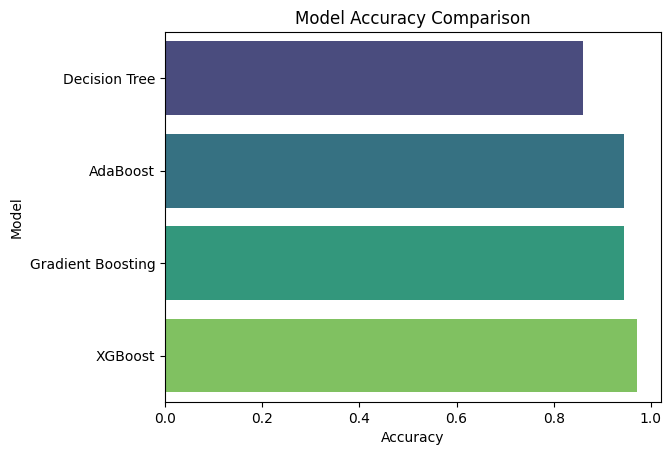

In [ ]:
import seaborn as sns
results = pd.DataFrame({
    'Model': ['Decision Tree', 'AdaBoost', 'Gradient Boosting', 'XGBoost'],
    'Accuracy': [
        accuracy_score(y_test, y_dt),
        accuracy_score(y_test, y_ada),
        accuracy_score(y_test, y_gb),
        accuracy_score(y_test, y_xgb)
    ]
})

sns.barplot(x='Accuracy', y='Model', data=results, palette='viridis')
plt.title("Model Accuracy Comparison")
plt.show()
